# Домашнее задание

В этом домашнем задании вам предстоит обучить модель классификации рукописных цифр на Tensorflow.

Важным дополнительным требованием будет сохранение чекпоинтов на ваш гугл диск (не переживайтеЖ ниже будут подсказки, как это сделать). Это пригодится вам в дальнейшем при обучении более сложных моделей, на случай потери данных при неожиданном отключении Colab.

In [2]:
import tensorflow as tf
print(tf.__version__)
from google.colab import drive
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

 #tf.enable_eager_execution()

2.19.0


####Вспомогательный код

In [3]:
#@title
def show_mnist(images, labels, predicted_labels=None):
    plt.figure(figsize=(10,10))
    for i in range(16):
        plt.subplot(4,4, i+1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i], cmap=plt.cm.gray)
        if predicted_labels is not None:
            title_obj = plt.title(f"Real: {labels[i]}. Pred: {predicted_labels[i]}")
            if labels[i] != predicted_labels[i]:
                plt.setp(title_obj, color='r')
        else:
            plt.title(f"Real label: {labels[i]}")

def show_progress(history: dict):
    plt.figure(figsize=(10, 5))
    ax1 = plt.subplot(1,2,1)
    plt.plot(history["acc"],label='train accuracy')
    plt.plot(history["val_acc"], label='test accuracy')
    ax2 = plt.subplot(1,2,2)
    plt.plot(history["loss"],label='train_loss')
    plt.plot(history["val_loss"],label='test_loss')

    ax1.legend(loc='best')
    ax2.legend(loc='best')
    plt.grid()
    plt.tight_layout()
    plt.show()

## Загрузка данных

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


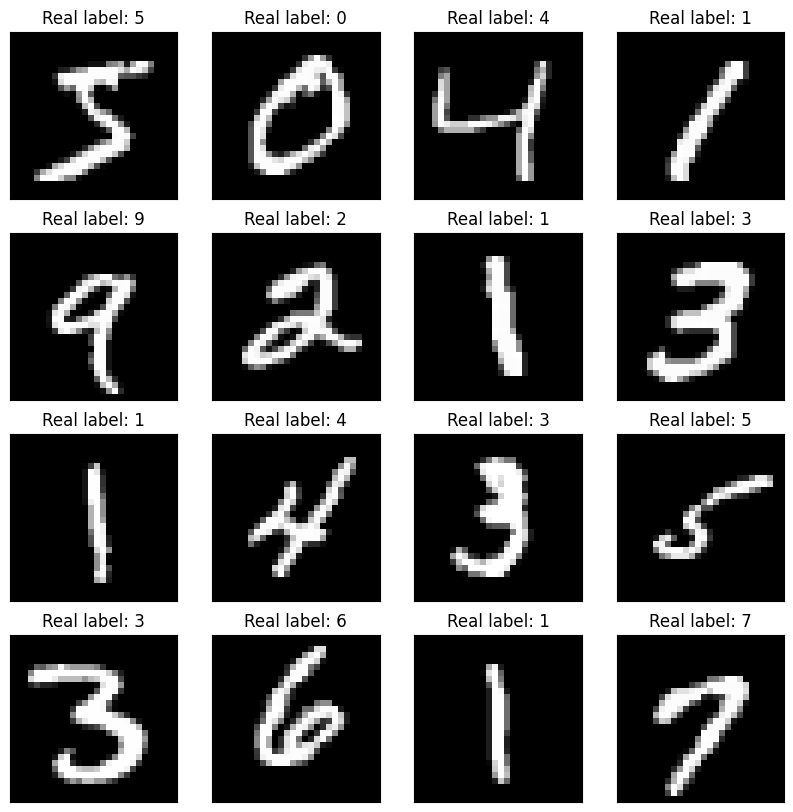

In [4]:
(x_train, y_train),(x_test, y_test) = tf.keras.datasets.mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

show_mnist(x_train, y_train)
x_train = x_train.reshape((-1, 28*28)) # вытянули каждую картинку в вектор
x_test = x_test.reshape((-1, 28*28))


In [5]:
# прикрепим ваш гугл диск к виртуальной машине
drive.mount('/content/drive/')

Mounted at /content/drive/


In [6]:
# Путь до вашего гугл диска скорее всего выглядит так: /content/drive/My Drive/
# если эта клетка вызывает ошибку,
# измените путь согласно ! ls "/content/drive/"

path = Path("/content/drive/My Drive/Skillbox/model_1")
path.mkdir(exist_ok=True, parents=True) # папка создается на вашем гугл диске. вместе с "родителями"
assert path.exists()
cpt_filename = "best_checkpoint.hdf5"
cpt_path =str(path / cpt_filename)
# После выполнения этой клетки, в вашем гугл диске должна создаться папка: Skillbox/model_1
# убедитесь в этом

А весь код ниже вы реализуете самостоятельно! Вы уже к этому готовы :)
Требования к модели:
1. Точность на тестовой части выборки >96%
2. Чекпоинт модели с лучшими параметрами должен быть сохранен у вас на гугл диске
3. Объект history, который получается из model.fit(...) должен содержать значения лосса и accuracy для трейна и теста

**Reasoning**:
Define a simple neural network model for classifying MNIST digits using PyTorch.



In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class SimpleNN(nn.Module):
    def __init__(self):
        super(SimpleNN, self).__init__()
        self.fc1 = nn.Linear(28 * 28, 128)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

## Define loss function and optimizer

### Subtask:
Set up the criterion and optimizer for training.


**Reasoning**:
Set up the criterion and optimizer for training as instructed.



In [8]:
model = SimpleNN()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

## Define training and evaluation functions

### Subtask:
Create functions to handle the training and evaluation loops for each epoch.


**Reasoning**:
Define the `train_epoch` and `evaluate_model` functions to handle the training and evaluation loops for each epoch, including moving data to the appropriate device.



In [9]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

def train_epoch(model, optimizer, criterion, data_loader):
    model.train()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    for inputs, labels in data_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_samples += labels.size(0)
        correct_predictions += (predicted == labels).sum().item()

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions / total_samples
    return epoch_loss, epoch_acc

def evaluate_model(model, criterion, data_loader):
    model.eval()
    running_loss = 0.0
    correct_predictions = 0
    total_samples = 0

    with torch.no_grad():
        for inputs, labels in data_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = model(inputs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

    epoch_loss = running_loss / total_samples
    epoch_acc = correct_predictions / total_samples
    return epoch_loss, epoch_acc

In [10]:
num_epochs = 10
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []
best_val_accuracy = 0.0

# Assuming x_train, y_train, x_test, y_test are already loaded and preprocessed
# and train_loader, test_loader are created from these using TensorDataset and DataLoader
# Also assuming path and cpt_path are defined for checkpoint saving

# Convert numpy arrays to torch tensors
x_train_tensor = torch.tensor(x_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
x_test_tensor = torch.tensor(x_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Create TensorDatasets
train_dataset = torch.utils.data.TensorDataset(x_train_tensor, y_train_tensor)
test_dataset = torch.utils.data.TensorDataset(x_test_tensor, y_test_tensor)

# Create DataLoaders
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=64, shuffle=False)


for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, optimizer, criterion, train_loader)
    val_loss, val_acc = evaluate_model(model, criterion, test_loader)

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} - Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    if val_acc > best_val_accuracy:
        best_val_accuracy = val_acc
        torch.save(model.state_dict(), cpt_path)
        print(f"Checkpoint saved to {cpt_path} with validation accuracy: {best_val_accuracy:.4f}")

history = {
    "loss": train_losses,
    "acc": train_accuracies,
    "val_loss": val_losses,
    "val_acc": val_accuracies
}

Epoch 1/10 - Train Loss: 0.3418, Train Acc: 0.9079, Val Loss: 0.1954, Val Acc: 0.9425
Checkpoint saved to /content/drive/My Drive/Skillbox/model_1/best_checkpoint.hdf5 with validation accuracy: 0.9425
Epoch 2/10 - Train Loss: 0.1566, Train Acc: 0.9545, Val Loss: 0.1259, Val Acc: 0.9626
Checkpoint saved to /content/drive/My Drive/Skillbox/model_1/best_checkpoint.hdf5 with validation accuracy: 0.9626
Epoch 3/10 - Train Loss: 0.1078, Train Acc: 0.9688, Val Loss: 0.0998, Val Acc: 0.9689
Checkpoint saved to /content/drive/My Drive/Skillbox/model_1/best_checkpoint.hdf5 with validation accuracy: 0.9689
Epoch 4/10 - Train Loss: 0.0799, Train Acc: 0.9765, Val Loss: 0.0855, Val Acc: 0.9740
Checkpoint saved to /content/drive/My Drive/Skillbox/model_1/best_checkpoint.hdf5 with validation accuracy: 0.9740
Epoch 5/10 - Train Loss: 0.0633, Train Acc: 0.9813, Val Loss: 0.0770, Val Acc: 0.9765
Checkpoint saved to /content/drive/My Drive/Skillbox/model_1/best_checkpoint.hdf5 with validation accuracy: 0.

In [11]:
restored_model = SimpleNN()
restored_model.load_state_dict(torch.load(cpt_path, map_location=device))
restored_model.to(device)

SimpleNN(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)

**Reasoning**:
Evaluate the restored model on the test set to verify the loaded weights.



In [12]:
loss, acc = evaluate_model(restored_model, criterion, test_loader)
print(f"Accuracy of restored model {acc*100 :.2f}%")
assert acc > 0.96

Accuracy of restored model 97.99%


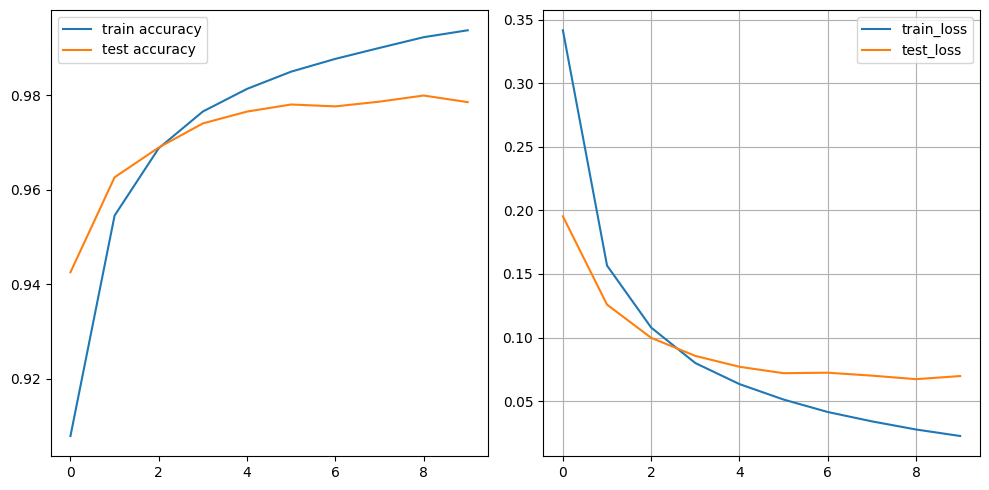

In [13]:
show_progress(history)